# Figure 1: Saturn recovers one isodepth per modality on simulated RNA + ATAC data

Fig. 1 introduces the Saturn model and tests it on simulated two-modality data. Each simulated section is a 30 x 30 grid
(900 spots) with 500 genes and 1,000 peaks. RNA and ATAC each follow their own isodepth, and every feature also reads the
other modality's isodepth through an additive cross term. The hard grid has 24 runs: angle between the two isodepths 45 or
90 degrees, RNA <- ATAC coupling 0.8 or 0.95, 60 or 90% of features coupled, and 3 seeds, with ATAC <- RNA coupling 0.2
and RNA depth 1,000.

The notebook simulates the 24 runs with `saturn.sim`, fits Saturn on each, scores how well each fitted axis recovers its
true axis and how much of the other true axis leaks into it, and draws panels c to e. Panels a and b are schematics. The
notebook covers Saturn only: the baseline methods of panels d and e (GASTON, MEFISTO, MISO, SCIGMA, SpatialGlue) and the
paired Wilcoxon brackets against them are not run here.

**Input data:** none. Every dataset is simulated from a seed.

**Conda env:** `spatialmultivelo`, CPU only. **Time:** about 4 min with 24 parallel processes of 2 torch threads each.

## Setup

The fits ran with 2 torch threads per process and `OMP_NUM_THREADS` unset, so the thread variables are removed before
numpy and torch are imported, and each worker sets 2 torch threads.

In [1]:
import os
for v in ("OMP_NUM_THREADS", "MKL_NUM_THREADS", "OPENBLAS_NUM_THREADS"):
    os.environ.pop(v, None)
import itertools
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from matplotlib.patches import FancyArrowPatch
from scipy.stats import spearmanr
from joblib import Parallel, delayed

import saturn
from saturn.sim import SimConfig, simulate
from saturn.theme import MODALITY, CMAP, ANCHOR, SATURN

saturn.theme.set_theme(7)
C_RNA, C_ATAC = MODALITY["RNA"], MODALITY["ATAC"]
INK, GREY = ANCHOR["ink"], ANCHOR["stone"]

WORK = Path(os.environ.get("SATURN_WORKSPACE", "saturn_workspace"))
PUB = WORK / "published"
OUT = WORK / "results" / "fig1"; (OUT / "axes").mkdir(parents=True, exist_ok=True)

## The hard grid

Each run is one `SimConfig`. The tag names the run as angle, RNA <- ATAC coupling, coupled fraction and seed.
`hard_a45_c0.8_0.6_s0` is the representative run of panels b and c: its recovery sits closest to the mean recovery over
all hard runs for every method of the full benchmark.

In [2]:
GRID = [dict(axis_angle_deg=a, cross_RA=c, cross_AR=0.2, coupled_frac=f, rna_libsize=1000.0, seed=s)
        for a, c, f, s in itertools.product([45, 90], [0.8, 0.95], [0.6, 0.9], range(3))]
tag = lambda g: f"hard_a{g['axis_angle_deg']}_c{g['cross_RA']}_{g['coupled_frac']}_s{g['seed']}"
PICK = "hard_a45_c0.8_0.6_s0"
print(len(GRID), "runs, e.g.", [tag(g) for g in GRID[:3]])

24 runs, e.g. ['hard_a45_c0.8_0.6_s0', 'hard_a45_c0.8_0.6_s1', 'hard_a45_c0.8_0.6_s2']


## Simulate and fit

For every run we simulate the counts and the targets (RNA GLM-PCs, ATAC LSI without component 1), z-score the coordinates
and fit Saturn with `train_saturn` at its defaults, seeded with the run's seed. The two scores are:

- **recovery**: |Spearman| between a fitted axis and its true axis;
- **leak**: the incremental R² of the other true axis in a fitted axis, beyond its own true axis, both entered as cubic
  polynomials. A raw correlation with the other true axis is not used, because at 45 degrees the two true axes already
  correlate.

The 24 runs go to 24 processes. The axes are saved per run, so a rerun of the notebook reuses them.

In [3]:
def abs_spearman(a, b):
    r = spearmanr(a, b).correlation
    return 0.0 if r is None or np.isnan(r) else abs(float(r))


def leak(v, own, other):
    """Incremental R2 of the other true axis in v, beyond the own true axis (cubic in each)."""
    def r2(X):
        X = np.c_[np.ones(len(v)), X]
        res = v - X @ np.linalg.lstsq(X, v, rcond=None)[0]
        return 1 - res.var() / (v.var() + 1e-12)
    P = lambda z: np.c_[z, z ** 2, z ** 3]
    return float(max(0.0, r2(np.c_[P(own), P(other)]) - r2(P(own))))


def run(g):
    torch.set_num_threads(2)
    d = simulate(SimConfig(**g))
    xy = saturn.zscore_coords(d.coords)
    model, _ = saturn.train_saturn([d.Y_R, d.Y_A], xy, seed=g["seed"], device="cpu")
    D = model.isodepth(torch.as_tensor(xy)).detach().numpy()
    np.savez_compressed(OUT / "axes" / f"{tag(g)}.npz", true=d.d, Saturn=D)
    return tag(g)


todo = [g for g in GRID if not (OUT / "axes" / f"{tag(g)}.npz").exists()]
Parallel(n_jobs=min(24, len(todo) or 1), backend="loky")(delayed(run)(g) for g in todo)

rows = []
for g in GRID:
    z = np.load(OUT / "axes" / f"{tag(g)}.npz"); T, D = z["true"], z["Saturn"]
    rows.append(dict(run=tag(g), angle=g["axis_angle_deg"], cross_RA=g["cross_RA"], coupled_frac=g["coupled_frac"],
                     seed=g["seed"], rec_R=abs_spearman(D[:, 0], T[:, 0]), rec_A=abs_spearman(D[:, 1], T[:, 1]),
                     leak_R=leak(D[:, 0], T[:, 0], T[:, 1]), leak_A=leak(D[:, 1], T[:, 1], T[:, 0])))
B = pd.DataFrame(rows); B.to_csv(OUT / "saturn_hard_grid.csv", index=False)
print(B[["rec_R", "rec_A", "leak_R", "leak_A"]].agg(["mean", "median", "min", "max"]).round(4).to_string())

         rec_R   rec_A  leak_R  leak_A
mean    0.9965  0.9997  0.0047  0.0005
median  0.9982  0.9997  0.0008  0.0002
min     0.9872  0.9992  0.0002  0.0000
max     0.9994  0.9999  0.0350  0.0028


Recovery and leak per condition, averaged over the 3 seeds.

In [4]:
print(B.groupby(["angle", "cross_RA", "coupled_frac"])[["rec_R", "rec_A", "leak_R", "leak_A"]].mean().round(3).to_string())

                             rec_R  rec_A  leak_R  leak_A
angle cross_RA coupled_frac                              
45    0.80     0.6           0.999  1.000   0.000   0.000
               0.9           0.999  1.000   0.002   0.000
      0.95     0.6           0.999  1.000   0.001   0.000
               0.9           0.997  1.000   0.003   0.000
90    0.80     0.6           0.999  1.000   0.001   0.001
               0.9           0.994  1.000   0.004   0.001
      0.95     0.6           0.997  1.000   0.006   0.000
               0.9           0.990  0.999   0.021   0.001


## Fig. 1a: assumption of Saturn

Fig. 1a is a schematic of the assumption behind Saturn (an own term and a cross term from the other modality's isodepth);
it is not drawn here.

## Fig. 1b: Saturn architecture

Fig. 1b is a schematic of the Saturn architecture (one encoder and isodepth per modality, own and cross pathways summed in
component space, reconstruction loss); it is not drawn here.

## Fig. 1c: generation of the benchmark data

Shown for one condition of the hard grid (θ = 45°, cross amplitude 0.8 from ATAC to RNA and 0.2 from RNA to ATAC, coupled
fraction 0.6, seed 0; 900 spots). Every tile and curve below is drawn from the simulator. Per row: (1) the modality's true
isodepth; (2) three piecewise-linear feature curves along it, with the domain boundaries shared by the axis; (3) for one
coupled feature, the own curve plus the cross curve of the other axis gives the log-rate; (4) the counts (RNA negative
binomial, ATAC Poisson); (5) the target component that tracks the true axis best.

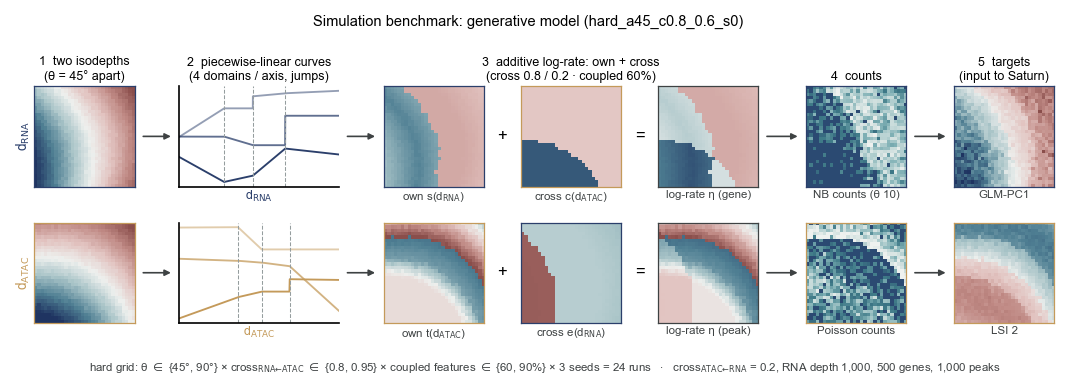

In [5]:
def z_(v):
    return (v - v.mean()) / (v.std() + 1e-12)


def tile(a, v, n, edge, cmap=CMAP["score"], lw=0.6):
    im = a.imshow(z_(v).reshape(n, n), cmap=cmap, origin="lower", vmin=-2, vmax=2, interpolation="nearest")
    a.set_xticks([]); a.set_yticks([])
    for s in a.spines.values():
        s.set_visible(True); s.set_edgecolor(edge); s.set_linewidth(lw)
    return im


def steepest_feature(F, coupled):
    """the coupled feature with the largest step between neighbouring sorted values, so a jump is visible"""
    idx = np.where(coupled)[0]
    return idx[np.argmax(np.abs(np.diff(np.sort(F[:, idx], 0), axis=0)).max(0))]


def fig_arrow(fig, a0, a1):
    p0, p1 = a0.get_position(), a1.get_position(); y = (p0.y0 + p0.y1) / 2
    fig.patches.append(FancyArrowPatch((p0.x1 + 0.004, y), (p1.x0 - 0.004, y), transform=fig.transFigure,
                                       arrowstyle="-|>", mutation_scale=6, lw=0.8, color=INK))


cfg = next(g for g in GRID if tag(g) == PICK)
d = simulate(SimConfig(**cfg)); n = d.config.n_side; P = d.parts
fig = plt.figure(figsize=(7.2, 2.5))
W = [1, 0.32, 1.5, 0.32, 1, 0.22, 1, 0.22, 1, 0.32, 1, 0.32, 1]
gs = GridSpec(3, len(W), figure=fig, width_ratios=W, height_ratios=[1, 1, 0.16], wspace=0.05, hspace=0.5,
              left=0.04, right=0.99, top=0.80, bottom=0.03)
ax = {}
for r, (m, col, oth) in enumerate((("RNA", C_RNA, "ATAC"), ("ATAC", C_ATAC, "RNA"))):
    own, crs = ("s", "c") if m == "RNA" else ("t", "e")
    f = steepest_feature(P[crs], d.coupled["R" if m == "RNA" else "A"])
    ax[r, 0] = fig.add_subplot(gs[r, 0]); tile(ax[r, 0], d.d[:, r], n, col)
    ax[r, 0].set_ylabel(f"d$_{{\\mathrm{{{m}}}}}$", fontsize=6.5, color=col, labelpad=1)
    ax[r, 2] = a = fig.add_subplot(gs[r, 2])
    o = np.argsort(d.d[:, r]); rng = np.random.default_rng(1)
    for i, j in enumerate(rng.choice(P[own].shape[1], 3, replace=False)):
        a.plot(d.d[o, r], P[own][o, j] + 2.6 * (i - 1), color=col, lw=0.9, alpha=1 - 0.25 * i)
    for b in d.breakpoints["R" if m == "RNA" else "A"]:
        a.axvline(b, color=GREY, lw=0.5, ls="--")
    a.set_xticks([]); a.set_yticks([]); a.set_xlim(0, 1)
    a.set_xlabel(f"d$_{{\\mathrm{{{m}}}}}$", fontsize=6, color=col, labelpad=1)
    ax[r, 4] = fig.add_subplot(gs[r, 4]); tile(ax[r, 4], P[own][:, f], n, col)
    ax[r, 6] = fig.add_subplot(gs[r, 6]); tile(ax[r, 6], P[crs][:, f], n, MODALITY[oth])
    ax[r, 8] = fig.add_subplot(gs[r, 8]); tile(ax[r, 8], P[own][:, f] + P[crs][:, f], n, INK)
    for c, s in ((5, "+"), (7, "=")):
        o_ = fig.add_subplot(gs[r, c]); o_.set_axis_off()
        o_.text(0.5, 0.5, s, fontsize=8, ha="center", va="center", transform=o_.transAxes)
    cnt, lib = (d.counts_R, d.counts_R.sum(1)) if m == "RNA" else (d.counts_A, d.counts_A.sum(1))
    ax[r, 10] = fig.add_subplot(gs[r, 10]); tile(ax[r, 10], np.log1p(1e3 * cnt[:, f] / lib), n, col, cmap=CMAP["pseudotime"])
    Y = d.Y_R if m == "RNA" else d.Y_A
    k = int(np.argmax([abs(np.corrcoef(Y[:, j], d.d[:, r])[0, 1]) for j in range(Y.shape[1])]))
    ax[r, 12] = fig.add_subplot(gs[r, 12]); tile(ax[r, 12], Y[:, k], n, col)
    labels = {4: f"own {own}(d$_{{\\mathrm{{{m}}}}}$)", 6: f"cross {crs}(d$_{{\\mathrm{{{oth}}}}}$)",
              8: f"log-rate η ({'gene' if m == 'RNA' else 'peak'})",
              10: "NB counts (θ 10)" if m == "RNA" else "Poisson counts",
              12: f"GLM-PC{k + 1}" if m == "RNA" else f"LSI {k + 2}"}
    for c, s in labels.items():
        ax[r, c].set_xlabel(s, fontsize=5.5, labelpad=1.5, color=INK)
fig.canvas.draw()
for r in (0, 1):
    for a0, a1 in ((0, 2), (2, 4), (8, 10), (10, 12)):
        fig_arrow(fig, ax[r, a0], ax[r, a1])
heads = {0: "1  two isodepths\n(θ = 45° apart)", 2: "2  piecewise-linear curves\n(4 domains / axis, jumps)",
         6: "3  additive log-rate: own + cross\n(cross 0.8 / 0.2 · coupled 60%)", 10: "4  counts", 12: "5  targets\n(input to Saturn)"}
for c, s in heads.items():
    ax[0, c].set_title(s, fontsize=6, pad=3)
foot = fig.add_subplot(gs[2, :]); foot.set_axis_off()
foot.text(0.5, 0.0, "hard grid: θ $\\in$ {45°, 90°} × cross$_{\\mathrm{RNA←ATAC}}$ $\\in$ {0.8, 0.95} × coupled features "
          "$\\in$ {60, 90%} × 3 seeds = 24 runs   ·   cross$_{\\mathrm{ATAC←RNA}}$ = 0.2, RNA depth 1,000, 500 genes, 1,000 peaks",
          fontsize=5.5, ha="center", va="bottom", color=INK, transform=foot.transAxes)
fig.suptitle(f"Simulation benchmark: generative model ({PICK})", fontsize=7, y=0.99)
plt.show()

## Fig. 1d: ground truth and the isodepths recovered by Saturn in the condition of c

Isodepths are z-scored, with the axis sign aligned to the truth for display. Values under each map are axis recovery
(absolute Spearman correlation with the true isodepth) and cross-axis leakage. The GASTON, MEFISTO, MISO, SCIGMA and
SpatialGlue maps are not drawn: these baselines are not run in this notebook.

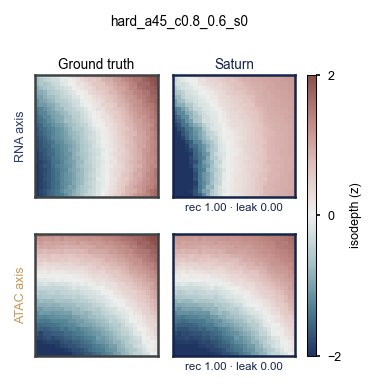

In [6]:
z = np.load(OUT / "axes" / f"{PICK}.npz"); T, D = z["true"], z["Saturn"]
row = B.set_index("run").loc[PICK]
fig = plt.figure(figsize=(2.6, 2.5))
gs = GridSpec(2, 3, figure=fig, width_ratios=[1, 1, 0.07], wspace=0.08, hspace=0.3, left=0.12, right=0.85,
              top=0.83, bottom=0.08)
for k, (lab, col, sfx) in enumerate((("RNA axis", C_RNA, "R"), ("ATAC axis", C_ATAC, "A"))):
    a = fig.add_subplot(gs[k, 0]); im = tile(a, T[:, k], 30, INK, lw=1.2)
    a.set_ylabel(lab, fontsize=6, color=col)
    v = D[:, k] if np.corrcoef(D[:, k], T[:, k])[0, 1] >= 0 else -D[:, k]
    b = fig.add_subplot(gs[k, 1]); tile(b, v, 30, SATURN, lw=1.2)
    b.text(0.5, -0.05, f"rec {row['rec_' + sfx]:.2f} · leak {row['leak_' + sfx]:.2f}", transform=b.transAxes,
           ha="center", va="top", fontsize=5.5, color=SATURN)
    if k == 0:
        a.set_title("Ground truth", fontsize=6.5, fontweight="bold", pad=3)
        b.set_title("Saturn", fontsize=6.5, fontweight="bold", pad=3, color=SATURN)
cb = fig.colorbar(im, cax=fig.add_subplot(gs[:, 2]), ticks=[-2, 0, 2]); cb.set_label("isodepth (z)", fontsize=6)
cb.ax.tick_params(labelsize=6, length=2); cb.outline.set_linewidth(0.5)
fig.suptitle(PICK, fontsize=6.5, y=0.99)
plt.show()

## Fig. 1e: axis recovery and cross-axis leakage over the hard grid

Axis recovery (top) and cross-axis leakage (bottom) over all runs of the hard grid (24 runs x 2 axes, n = 48 axes). The
violin shows the distribution, points individual axes, the black bar the interquartile range and the white dot the median.
The baseline methods and the one-sided paired Wilcoxon brackets against them are not drawn: the baselines are not run here.

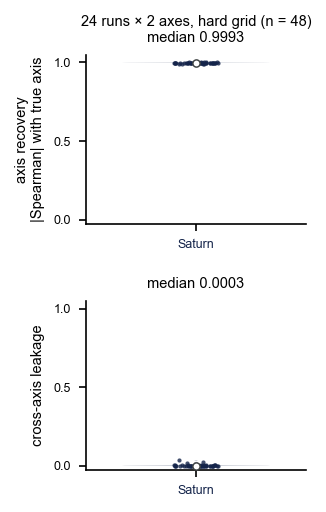

         rec                    leak                
      median     min     max  median     min     max
axis                                                
ATAC  0.9997  0.9992  0.9999  0.0002  0.0000  0.0028
RNA   0.9982  0.9872  0.9994  0.0008  0.0002  0.0350


In [7]:
L = pd.concat([B.assign(axis="RNA", rec=B.rec_R, leak=B.leak_R), B.assign(axis="ATAC", rec=B.rec_A, leak=B.leak_A)])


def violin(ax, v, ylabel):
    rng = np.random.default_rng(0)
    parts = ax.violinplot([v], positions=[0], widths=0.8, showextrema=False, bw_method=0.3)
    for b in parts["bodies"]:
        b.set_facecolor(SATURN); b.set_edgecolor("none"); b.set_alpha(0.35)
    ax.scatter(rng.uniform(-0.12, 0.12, len(v)), v, s=4, lw=0, color=SATURN, alpha=0.8, zorder=2)
    q1, med, q3 = np.percentile(v, [25, 50, 75])
    ax.plot([0, 0], [q1, q3], color=INK, lw=1.6, zorder=3)
    ax.scatter([0], [med], s=12, color="white", edgecolor=INK, lw=0.7, zorder=4)
    ax.set_xticks([0]); ax.set_xticklabels(["Saturn"], color=SATURN)
    ax.set_xlim(-0.6, 0.6); ax.set_ylim(-0.03, 1.05); ax.set_yticks([0, 0.5, 1.0])
    ax.set_ylabel(ylabel)
    return med


fig, (top, bottom) = plt.subplots(2, 1, figsize=(1.9, 3.6), gridspec_kw=dict(hspace=0.45))
m1 = violin(top, L.rec.values, "axis recovery\n|Spearman| with true axis")
m2 = violin(bottom, L.leak.values, "cross-axis leakage")
top.set_title(f"{len(B)} runs × 2 axes, hard grid (n = {len(L)})\nmedian {m1:.4f}", fontsize=7)
bottom.set_title(f"median {m2:.4f}", fontsize=7)
plt.show()
print(L.groupby("axis")[["rec", "leak"]].agg(["median", "min", "max"]).round(4).to_string())